# Beyond the heatmap: a visual benchmark gallery

**Which solver fits your MDP? Where can your solver win?**

This notebook explores four complementary views of existing measurements. It
reads saved CSVs and does **not** build models or run solvers. Plot functions stay
here while we explore the design; `BenchmarkResult.plot_heat()` offers the
library heatmap, implemented in `src/mdpforge/utils/plotting.py`.

| View | Question | Useful for |
| --- | --- | --- |
| Speedup with repeat spread | Where does a solver beat the reference? | A compact README introduction |
| Performance profile | How often is a solver close to the fastest? | Comparing a broad benchmark suite |
| Outcome breakdown | How many models pass every repeat? | Showing robustness alongside speed |
| Runtime vs value-error bound | Did the fast result meet the accuracy target? | Explaining the scientific contract |

From the repository root, install `python -m pip install -e ".[notebooks]"` and
select a Python 3.11+ kernel with that installation. No solver backend is required
to render saved results. Run the notebook from the root or from `notebooks/`.

Two exports are kept separate: the small README comparison and the larger
backend comparison. **The latter was recorded on 2026-10-09 with MDPSolver
0.10.1, before the VISOR fix.** It illustrates the plots, not current backend
performance. Re-run `benchmark_backends.ipynb` to obtain fresh measurements.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError("Run from the repository root or its notebooks/ directory")

# Replace these with your own Benchmark.export_csv() files. Do not combine runs.
DEMO_CSV = ROOT / "artifacts/results/readme_benchmark.csv"
SUITE_CSV = ROOT / "artifacts/results/backends_benchmark.csv"
OUTPUT_DIR = ROOT / "artifacts/figures"
REFERENCE = "VI"

LABELS = {
    "VI": "VI · reference",
    "mdpforge_mpi": "MPI · mdpforge",
    "mdptoolbox_mpi": "MPI · MDPToolbox",
    "bertsekas_pi": "PI · Bertsekas",
}
MODEL_LABELS = {
    "200_10_garnet_0.85_1.0": "Garnet",
    "100_2_chain_walk": "Chain Walk",
    "100_4_rooms": "Rooms",
}
INK, MUTED, GRID = "#142c40", "#526879", "#dae4ec"
DEMO_COLORS = ["#75889a", "#2563eb", "#008c87", "#d07816"]

STYLE = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.edgecolor": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "#f8fafc",
    "axes.facecolor": "#ffffff",
    "savefig.facecolor": "#f8fafc",
    "svg.fonttype": "none",
}


def load_results(path):
    df = pd.read_csv(path)
    required = {
        "model",
        "solver",
        "repeat",
        "seed",
        "state_dim",
        "action_dim",
        "discount",
        "epsilon",
        "runtime",
        "error_bound",
        "status",
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    if df.empty or df[["model", "solver", "status"]].isna().any().any():
        raise ValueError("Results need nonempty model, solver and status fields")
    settings = ["discount", "epsilon"]
    if "experiment_id" in df:
        settings.append("experiment_id")
    if len(df[settings].drop_duplicates()) != 1:
        raise ValueError(
            "Select one experiment, discount and precision before plotting"
        )
    if not np.isfinite(df[["discount", "epsilon"]].iloc[0]).all():
        raise ValueError("Discount and precision must be finite")
    if not 0 < df["discount"].iloc[0] < 1 or not df["epsilon"].iloc[0] > 0:
        raise ValueError("Discount and precision must satisfy the benchmark contract")
    if df.duplicated(["model", "solver", "repeat"]).any():
        raise ValueError("Duplicate trials: do not merge distinct benchmark runs")
    for model, rows in df.groupby("model", sort=False):
        if len(rows[["state_dim", "action_dim"]].drop_duplicates()) != 1:
            raise ValueError(f"Different dimensions for the same model name: {model}")
        if rows.groupby("repeat")["seed"].nunique().gt(1).any():
            raise ValueError(f"Unpaired trial seeds for model: {model}")
    successful = df["status"].eq("success")
    certified = (
        np.isfinite(df["runtime"])
        & df["runtime"].gt(0)
        & np.isfinite(df["error_bound"])
        & df["error_bound"].ge(0)
        & df["error_bound"].le(df["epsilon"])
    )
    if (successful & ~certified).any():
        raise ValueError("A success row has an invalid runtime or value-error bound")
    manifest_file = path.with_suffix(".experiment.json")
    if manifest_file.is_file():
        saved = json.loads(manifest_file.read_text(encoding="utf-8"))
        if (
            "experiment_id" in df
            and saved["experiment_id"] != df["experiment_id"].iloc[0]
        ):
            raise ValueError("CSV and experiment manifest do not match")
        df.attrs["expected_repeats"] = set(range(1, saved["settings"]["repeats"] + 1))
    return df


def summarize(df):
    """A median is eligible only when every recorded, expected repeat succeeded."""
    models = list(df["model"].unique())
    solvers = list(df["solver"].unique())
    times = pd.DataFrame(np.nan, index=models, columns=solvers)
    complete = pd.DataFrame(False, index=models, columns=solvers)
    for model in models:
        rows = df.loc[df["model"].eq(model)]
        expected = df.attrs.get("expected_repeats", set(rows["repeat"]))
        for solver in solvers:
            group = rows.loc[rows["solver"].eq(solver)]
            passed = not group.empty and set(group["repeat"]) == expected
            passed = passed and group["status"].eq("success").all()
            complete.loc[model, solver] = passed
            if passed:
                times.loc[model, solver] = group["runtime"].median()
    return times, complete


def export_figure(fig, name, source):
    if source == SUITE_CSV and manifest_path.is_file():
        recorded = manifest["created_at_utc"][:10]
        backend = manifest["environment"]["backends"].get("mdpsolver", {})
        provenance = f"Historical export · {recorded} · MDPSolver {backend.get('version')} · {source.name}"
    else:
        provenance = f"Saved measurements · {source.name} · timings depend on hardware"
    bottom = min([0.0] + [text.get_position()[1] for text in fig.texts])
    fig.text(0.02, bottom - 0.045, provenance, fontsize=8, color=MUTED)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "svg"):
        fig.savefig(OUTPUT_DIR / f"{name}.{extension}", dpi=180, bbox_inches="tight")
    display(fig)
    plt.close(fig)


demo = load_results(DEMO_CSV)
suite = load_results(SUITE_CSV)
print(
    f"README sample: {demo.model.nunique()} models, {demo.solver.nunique()} solvers, {len(demo)} trials"
)
print(
    f"Backend snapshot: {suite.model.nunique()} models, {suite.solver.nunique()} solvers, {len(suite)} trials"
)

# Report provenance rather than assuming saved timings use today's installation.
manifest_path = SUITE_CSV.with_suffix(".experiment.json")
if manifest_path.is_file():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    print("Recorded at:", manifest["created_at_utc"])
    print("Backend versions:", manifest["environment"]["backends"])
else:
    print("No matching experiment manifest; verify the provenance of this export.")

README sample: 3 models, 4 solvers, 36 trials
Backend snapshot: 51 models, 17 solvers, 2601 trials
Recorded at: 2026-10-09T15:55:33.721490+00:00
Backend versions: {'marmote': {'distribution': 'marmote', 'version': None}, 'mazelib': {'distribution': 'mazelib', 'version': '0.9.16'}, 'mdpsolver': {'distribution': 'mdpsolver', 'version': '0.10.1'}, 'mdptoolbox': {'distribution': 'pymdptoolbox', 'version': '4.0b3'}, 'tqdm': {'distribution': 'tqdm', 'version': '4.67.3'}}


## 1. Speedup and repeat spread: the README view

Each point is a **paired trial speedup**: reference runtime / solver runtime for
the same model, repeat and seed. A value of 2× means the solver took half the
reference time. Large points are medians of these ratios; horizontal bars span
the minimum and maximum, not a confidence interval. Three repeats show observed
spread, not statistical significance. This differs slightly from the heatmap's
ratio of median runtimes.

The 1× line is the reference. A model/solver pair with any failed or missing
repeat is labelled `FAIL / incomplete`, without a speedup. No successful subset
is used to hide failures. A missing reference leaves the whole panel unavailable.

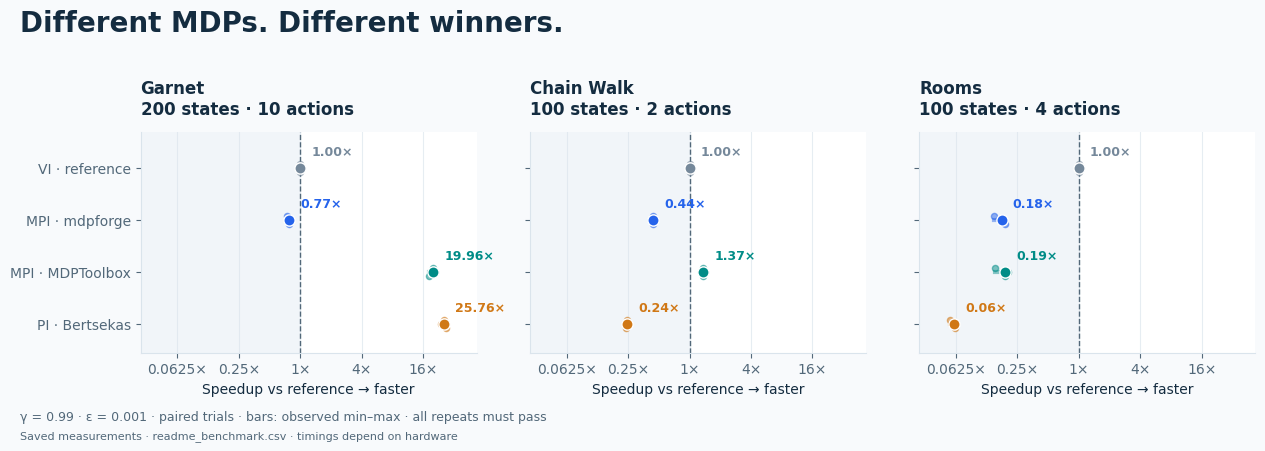

In [2]:
def plot_speedups(df, reference):
    times, complete = summarize(df)
    models, solvers = list(times.index), list(times.columns)
    if reference not in solvers:
        raise ValueError(f"Reference solver is absent: {reference}")
    colors = dict(zip(solvers, plt.get_cmap("tab10").colors * (1 + len(solvers) // 10)))
    if len(solvers) <= len(DEMO_COLORS):
        colors = dict(zip(solvers, DEMO_COLORS))
    ratios = {}
    for model in models:
        if not complete.loc[model, reference]:
            continue
        rows = df.loc[df["model"].eq(model)]
        ref = rows.loc[rows["solver"].eq(reference)].set_index(["repeat", "seed"])[
            "runtime"
        ]
        for solver in solvers:
            if complete.loc[model, solver]:
                runtime = rows.loc[rows["solver"].eq(solver)].set_index(
                    ["repeat", "seed"]
                )["runtime"]
                ratios[model, solver] = (ref / runtime).to_numpy()
    values = np.concatenate(list(ratios.values())) if ratios else np.array([1.0])
    lower, upper = min(0.8, values.min() / 2), max(1.25, values.max() * 2)
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(
            1,
            len(models),
            figsize=(4.25 * len(models), 3.9),
            squeeze=False,
            sharey=True,
        )
        for ax, model in zip(axes[0], models):
            dims = df.loc[df["model"].eq(model)].iloc[0]
            ax.set_title(
                f"{MODEL_LABELS.get(model, model)}\n{int(dims.state_dim)} states · {int(dims.action_dim)} actions",
                loc="left",
                fontsize=12,
                fontweight="bold",
                pad=13,
            )
            ax.axvspan(lower, 1, color="#f1f5f9", zorder=0)
            ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
            for position, solver in enumerate(solvers):
                y = len(solvers) - 1 - position
                samples = ratios.get((model, solver))
                if samples is None:
                    ax.text(
                        0.02,
                        y,
                        "FAIL / incomplete",
                        transform=ax.get_yaxis_transform(),
                        color="#b44242",
                        fontsize=9,
                    )
                    continue
                median = np.median(samples)
                ax.plot(
                    [samples.min(), samples.max()],
                    [y, y],
                    color=colors[solver],
                    linewidth=3,
                    alpha=0.45,
                )
                ax.scatter(
                    samples,
                    y + np.linspace(-0.08, 0.08, len(samples)),
                    color=colors[solver],
                    s=20,
                    alpha=0.5,
                    zorder=3,
                )
                ax.scatter(
                    [median],
                    [y],
                    s=65,
                    color=colors[solver],
                    edgecolor="white",
                    linewidth=1,
                    zorder=4,
                )
                ax.annotate(
                    f"{median:.2f}×",
                    (median, y),
                    xytext=(8, 9),
                    textcoords="offset points",
                    fontsize=9,
                    fontweight="bold",
                    color=colors[solver],
                )
            ax.set_xscale("log", base=2)
            ax.set_xlim(lower, upper)
            ticks = [
                2.0**n
                for n in range(
                    int(np.ceil(np.log2(lower))), int(np.floor(np.log2(upper))) + 1
                )
                if n % 2 == 0
            ]
            ax.set_xticks(ticks)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}×"))
            ax.set_yticks(
                range(len(solvers)), [LABELS.get(s, s) for s in reversed(solvers)]
            )
            ax.set_ylim(-0.55, len(solvers) - 0.3)
            ax.grid(axis="x", color=GRID, alpha=0.65)
            ax.set_axisbelow(True)
            ax.set_xlabel("Speedup vs reference → faster")
        fig.suptitle(
            "Different MDPs. Different winners.",
            x=0.02,
            ha="left",
            fontsize=20,
            fontweight="bold",
            y=1.03,
        )
        settings = df.iloc[0]
        fig.text(
            0.02,
            -0.025,
            f"γ = {settings.discount:g} · ε = {settings.epsilon:g} · paired trials · bars: observed min–max · all repeats must pass",
            fontsize=9,
            color=MUTED,
        )
        fig.tight_layout()
    return fig


export_figure(plot_speedups(demo, REFERENCE), "readme_speedups", DEMO_CSV)

## 2. Performance profile: consistent speed across models

For each model, divide a solver's median runtime by the fastest **eligible**
median across all selected solvers. The curve at a factor $\tau$ shows the share
of models solved within $\tau$ times the fastest. At 1× it counts wins, including
ties; at 2× it counts models within twice the best time. Higher is better.

All models remain in the denominator. Failed, incomplete, or absent solver/model
pairs have infinite ratios; a model with no eligible solver contributes zero to
every curve. Repeats receive equal weight within a median, and **models** receive
equal weight in the profile. No averaging of raw runtimes across unrelated MDPs.

This follows the [performance profile idea of Dolan and Moré](https://doi.org/10.1007/S101070100263).
The panels share the same global fastest times, not separate family baselines.
The display stops at 100×; a lower endpoint can mean slow solves or failures.
Use the outcome plot below to distinguish them. Family membership is inferred
from the saved solver names for this historical backend export.

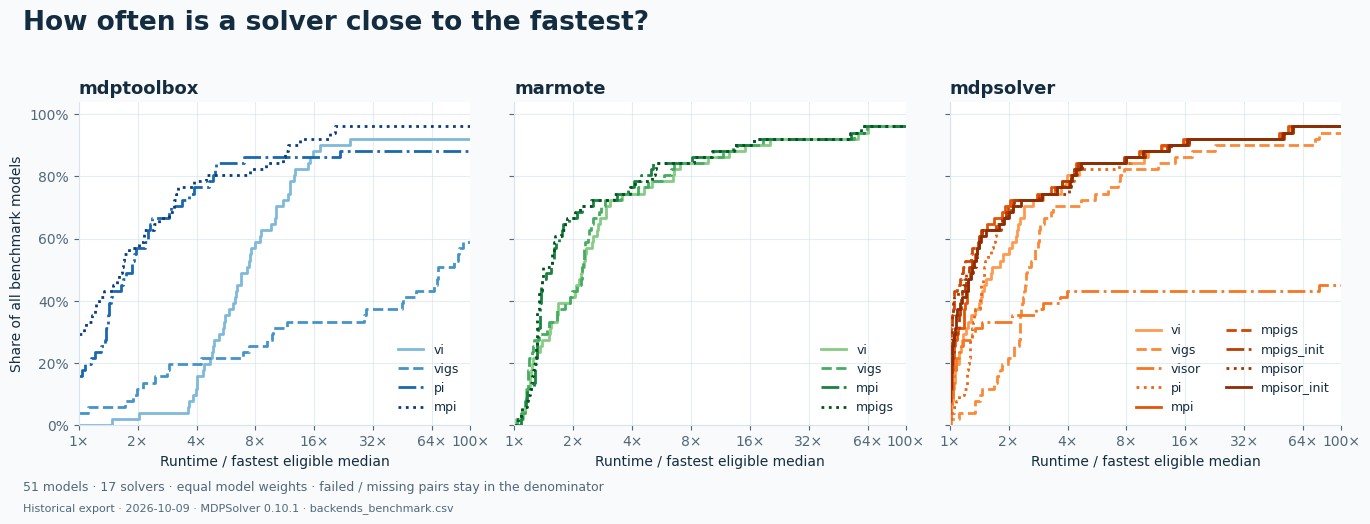

In [3]:
def plot_profiles(df, max_factor=100):
    if not np.isfinite(max_factor) or max_factor <= 1:
        raise ValueError("max_factor must be finite and greater than one")
    times, complete = summarize(df)
    ratios = times.div(times.min(axis=1), axis=0).fillna(np.inf)
    families = {}
    for solver in times.columns:
        family = solver.split("_", 1)[0]
        families.setdefault(family, []).append(solver)
    palettes = {"mdptoolbox": "Blues", "marmote": "Greens", "mdpsolver": "Oranges"}
    styles = ["-", "--", "-.", ":"]
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(
            1,
            len(families),
            figsize=(4.6 * len(families), 4.6),
            sharey=True,
            squeeze=False,
        )
        for ax, (family, solvers) in zip(axes[0], families.items()):
            palette = plt.get_cmap(palettes.get(family, "viridis"))
            for i, solver in enumerate(solvers):
                r = ratios[solver].to_numpy()
                finite = r[np.isfinite(r) & (r <= max_factor)]
                x = np.unique(np.r_[1.0, finite, max_factor])
                y = (r[:, None] <= x[None, :]).mean(axis=0)
                ax.step(
                    x,
                    y,
                    where="post",
                    label=solver.removeprefix(family + "_"),
                    color=palette(0.45 + 0.5 * i / max(1, len(solvers) - 1)),
                    linestyle=styles[i % len(styles)],
                    linewidth=2,
                )
            ax.set_xscale("log", base=2)
            ticks = [t for t in (1, 2, 4, 8, 16, 32, 64, 100) if t <= max_factor]
            ax.set_xticks(ticks)
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}×"))
            ax.set_xlim(1, max_factor)
            ax.set_ylim(0, 1.04)
            ax.yaxis.set_major_formatter(PercentFormatter(1))
            ax.grid(color=GRID, alpha=0.65)
            ax.set_title(family, loc="left", fontweight="bold", fontsize=13)
            ax.set_xlabel("Runtime / fastest eligible median")
            ax.legend(
                loc="lower right",
                frameon=False,
                fontsize=9,
                ncol=2 if len(solvers) > 4 else 1,
            )
        axes[0, 0].set_ylabel("Share of all benchmark models")
        fig.suptitle(
            "How often is a solver close to the fastest?",
            x=0.02,
            ha="left",
            fontsize=19,
            fontweight="bold",
            y=1.03,
        )
        fig.text(
            0.02,
            -0.015,
            f"{len(times)} models · {len(times.columns)} solvers · equal model weights · failed / missing pairs stay in the denominator",
            fontsize=9,
            color=MUTED,
        )
        fig.tight_layout()
    return fig


export_figure(plot_profiles(suite), "gallery_performance_profiles", SUITE_CSV)

## 3. Outcome breakdown: speed needs coverage

Left: the share of recorded trials in each status. Right: the number of models
for which **all expected repeats succeeded**. These are different quantities:
two successful trials out of three do not count as a fully solved model.
Missing model/solver pairs reduce coverage, without being relabelled as errors.
The trial denominator is printed so absent trials are not hidden.

Sort by full-model coverage, using alphabetical order for ties. Colours distinguish
success, timeout, error and missed precision. This historical plot shows the
old VISOR failures; it does not claim that MDPSolver 0.10.2 still has them.

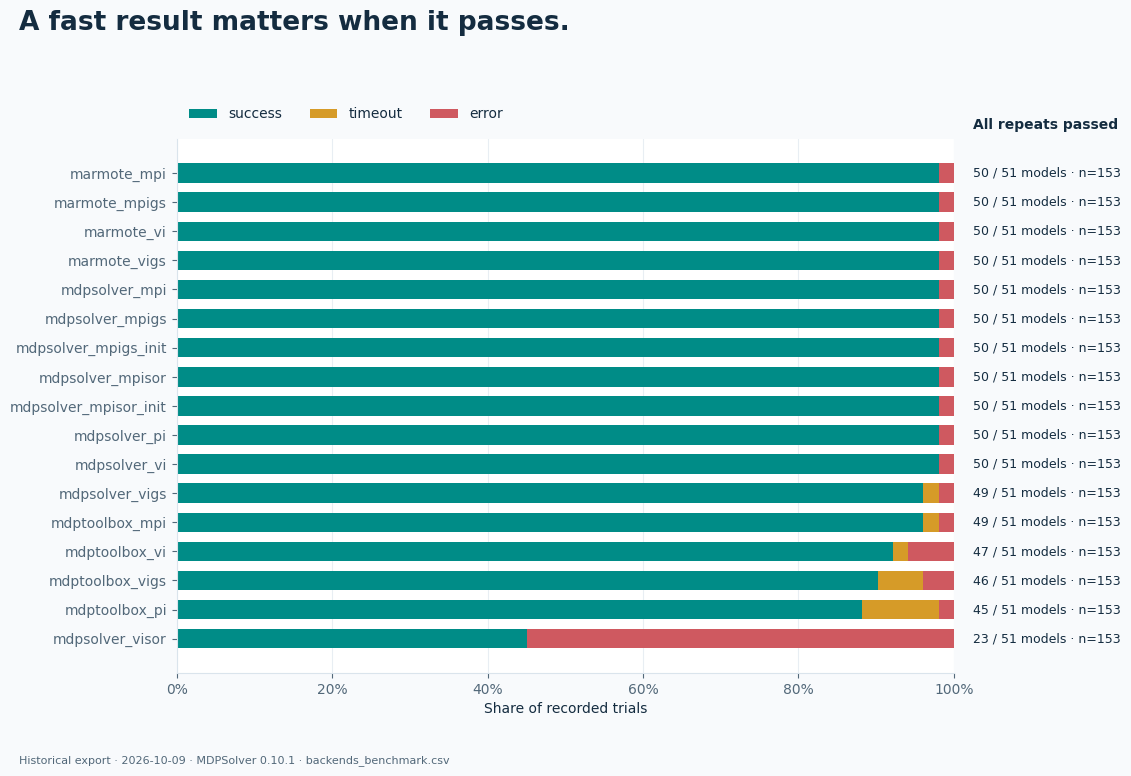

In [4]:
def plot_outcomes(df):
    times, complete = summarize(df)
    coverage = complete.sum().sort_index().sort_values(ascending=False, kind="stable")
    order = list(coverage.index)
    counts = pd.crosstab(df["solver"], df["status"]).reindex(order, fill_value=0)
    statuses = [s for s in ("success", "timeout", "imprecise", "error") if s in counts]
    statuses += sorted(set(counts.columns) - set(statuses))
    total = counts.sum(axis=1)
    colors = {
        "success": "#008c87",
        "timeout": "#d69b28",
        "imprecise": "#8461c5",
        "error": "#cf5960",
    }
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(11.8, max(3.5, 0.32 * len(order) + 1.7)))
        left = np.zeros(len(order))
        for status in statuses:
            fraction = counts[status].to_numpy() / total.to_numpy()
            ax.barh(
                range(len(order)),
                fraction,
                left=left,
                color=colors.get(status, "#75889a"),
                label=status,
                height=0.67,
            )
            left += fraction
        ax.set_yticks(range(len(order)), order)
        ax.invert_yaxis()
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.set_xlabel("Share of recorded trials")
        ax.grid(axis="x", color=GRID, alpha=0.6)
        ax.set_axisbelow(True)
        for i, solver in enumerate(order):
            ax.text(
                1.025,
                i,
                f"{int(coverage[solver]):>2} / {len(times)} models · n={int(total[solver])}",
                transform=ax.get_yaxis_transform(),
                va="center",
                fontsize=9,
                color=INK,
            )
        ax.text(
            1.025,
            1.02,
            "All repeats passed",
            transform=ax.transAxes,
            fontsize=10,
            fontweight="bold",
        )
        ax.legend(
            loc="lower left",
            bbox_to_anchor=(0, 1.01),
            ncol=len(statuses),
            frameon=False,
        )
        fig.suptitle(
            "A fast result matters when it passes.",
            x=0.02,
            ha="left",
            fontsize=19,
            fontweight="bold",
            y=1.01,
        )
        fig.tight_layout(rect=(0, 0, 0.97, 0.96))
    return fig


export_figure(plot_outcomes(suite), "gallery_outcomes", SUITE_CSV)

## 4. Runtime vs accuracy: explain what 'success' means

The vertical coordinate is **certified value-error bound / requested precision**,
not the unknown actual error. Values at or below 1 meet the target. Move left to
find faster runs; moving down indicates a tighter bound, not necessarily a better
policy. Colours identify solvers; circles are successful trials and crosses are
other statuses with finite runtime and bound. These are per-trial points.

Timeouts or crashes without finite coordinates cannot appear here. Their count
is printed; they stay visible in the outcome chart. Exact zero bounds are drawn
at $10^{-12}$ to support the log axis. The minimum plotted ratio is a display
floor, not a replacement of any stored measurement. Separate model panels avoid
mixing distinct problems into a misleading global time/accuracy frontier.

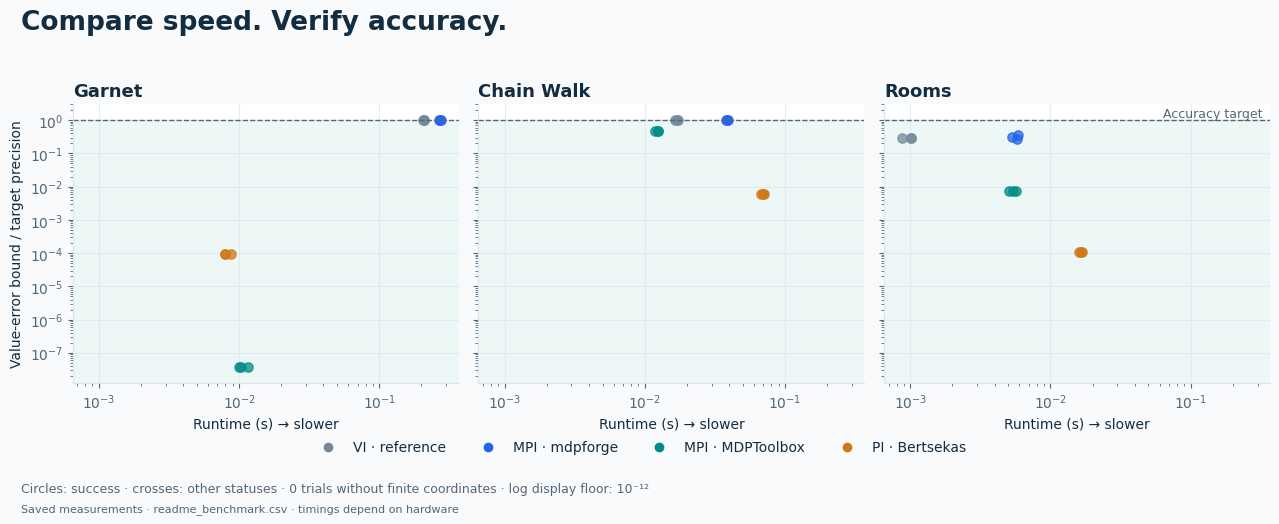

In [5]:
def plot_accuracy(df):
    models, solvers = list(df.model.unique()), list(df.solver.unique())
    colors = dict(zip(solvers, plt.get_cmap("tab10").colors * (1 + len(solvers) // 10)))
    if len(solvers) <= len(DEMO_COLORS):
        colors = dict(zip(solvers, DEMO_COLORS))
    valid = (
        np.isfinite(df.runtime)
        & df.runtime.gt(0)
        & np.isfinite(df.error_bound)
        & df.error_bound.ge(0)
    )
    drawable = df.loc[valid].copy()
    drawable["relative_bound"] = (drawable.error_bound / drawable.epsilon).clip(
        lower=1e-12
    )
    if drawable.empty:
        raise ValueError("No trials have finite runtime and error-bound coordinates")
    ymin = max(1e-12, drawable.relative_bound.min() / 3)
    ymax = max(3, drawable.relative_bound.max() * 3)
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(
            1,
            len(models),
            figsize=(4.3 * len(models), 4.2),
            squeeze=False,
            sharey=True,
            sharex=True,
        )
        for ax, model in zip(axes[0], models):
            ax.axhspan(ymin, 1, color="#e6f5f1", alpha=0.7, zorder=0)
            ax.axhline(1, color=MUTED, linestyle="--", linewidth=1)
            for solver in solvers:
                rows = drawable.loc[
                    drawable.model.eq(model) & drawable.solver.eq(solver)
                ]
                for passed, marker in ((True, "o"), (False, "x")):
                    points = rows.loc[rows.status.eq("success").eq(passed)]
                    ax.scatter(
                        points.runtime,
                        points.relative_bound,
                        color=colors[solver],
                        s=45,
                        marker=marker,
                        alpha=0.75,
                    )
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_ylim(ymin, ymax)
            ax.grid(color=GRID, alpha=0.65)
            ax.set_axisbelow(True)
            ax.set_title(
                MODEL_LABELS.get(model, model),
                loc="left",
                fontweight="bold",
                fontsize=13,
            )
            ax.set_xlabel("Runtime (s) → slower")
        axes[0, 0].set_ylabel("Value-error bound / target precision")
        axes[0, -1].text(
            0.98,
            1,
            "Accuracy target",
            transform=axes[0, -1].get_yaxis_transform(),
            ha="right",
            va="bottom",
            fontsize=9,
            color=MUTED,
        )
        handles = [
            plt.Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                color=colors[s],
                label=LABELS.get(s, s),
            )
            for s in solvers
        ]
        fig.legend(
            handles=handles,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.05),
            ncol=min(4, len(solvers)),
            frameon=False,
        )
        fig.suptitle(
            "Compare speed. Verify accuracy.",
            x=0.02,
            ha="left",
            fontsize=19,
            fontweight="bold",
            y=1.04,
        )
        fig.text(
            0.02,
            -0.11,
            f"Circles: success · crosses: other statuses · {int((~valid).sum())} trials without finite coordinates · log display floor: 10⁻¹²",
            fontsize=9,
            color=MUTED,
        )
        fig.tight_layout()
    return fig


export_figure(plot_accuracy(demo), "readme_accuracy", DEMO_CSV)

## Use these views with your own results

Replace the two CSV paths in the setup cell, or pass a DataFrame from a fresh
`Benchmark.run()` directly to the plot functions. Keep one experiment and one
discount/precision per comparison. Use your solver's saved label for `REFERENCE`.
Update `LABELS` and `MODEL_LABELS` for presentation without altering the raw data.

All four figures are exported to `artifacts/figures/` as PNG for GitHub and SVG
for editing. The 3-model README sample illustrates how rankings depend on the
MDP; it cannot establish general superiority. The 51-model backend export is a
historical default-dimension sample, not a controlled scalability experiment.
Changing the compared solver set can change performance profiles.

**Next experiments:** size sweeps within a single model family; discount and
precision sweeps; Bellman-residual traces over iterations or elapsed time. These
need new measurements (and trace instrumentation for convergence), so we do not
infer curves from the current final-result CSVs. See the
[visualization roadmap](../docs/visualization-roadmap.md) for README priorities.